# Customer Response Prediction — Data Loading, EDA & Preprocessing

## 1. Problem Definition
A Portuguese bank calls clients to sell a **term deposit**. We want to predict which clients will **subscribe** (`y = yes`), so the bank can focus its calls on them.

- **Dataset:** [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) — `bank-additional-full.csv`
- **Target:** `y` (yes / no) → binary classification
- **Output of this notebook:** a cleaned dataset ready for the models

## 2. Import Libraries

In [1]:
# Data handling
import io
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 3. Load the Dataset

In [2]:
# Download the dataset from UCI (only the first time)
DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
RAW_PATH = "data/bank-additional-full.csv"

if not os.path.exists(RAW_PATH):
    os.makedirs("data", exist_ok=True)
    with urllib.request.urlopen(DATA_URL) as r:
        outer = zipfile.ZipFile(io.BytesIO(r.read()))
    # the UCI zip contains another zip with the CSV inside
    inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
    with open(RAW_PATH, "wb") as f:
        f.write(inner.read("bank-additional/bank-additional-full.csv"))

# The file uses ";" as separator
df = pd.read_csv(RAW_PATH, sep=";")

## 4. Data Understanding

In [3]:
# First 5 rows
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Last 5 rows
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [5]:
# Number of rows and columns
df.shape

(41188, 21)

In [6]:
# Column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [7]:
# Summary statistics of numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [8]:
# Column groups used in the rest of the notebook
TARGET = "y"
cat_cols = df.select_dtypes(exclude="number").columns.drop(TARGET).tolist()
num_cols = df.select_dtypes("number").columns.tolist()
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [9]:
# Summary of categorical columns
df[cat_cols + [TARGET]].describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


**Column meaning**
- **Client:** `age`, `job`, `marital`, `education`, `default`, `housing`, `loan`
- **Last call:** `contact`, `month`, `day_of_week`, `duration` (seconds)
- **Campaign:** `campaign` (calls in this campaign), `pdays` (days since the last contact of a previous campaign, 999 = no value recorded), `previous` (contacts before this campaign), `previous`, `poutcome`
- **Economy:** `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed`

## 5. Data Cleaning
### 5.1 Missing Values

In [10]:
# Missing values per column
df.isnull().sum().sum()

np.int64(0)

In [11]:
# Missing information is stored as the text "unknown"
unknown = (df == "unknown").sum()
pd.DataFrame({"unknown": unknown, "percent": (unknown / len(df) * 100).round(2)}).query("unknown > 0")

,unknown,percent
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40


**Decision:** keep `"unknown"` as its own category. Dropping these rows would lose many clients (`default` alone has 21% unknown).

### 5.2 Duplicates

In [12]:
df.duplicated().sum()

np.int64(12)

In [13]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(41176, 21)

### 5.3 Outliers

In [14]:
# IQR method: count values outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    rows.append({"column": col, "lower": lower, "upper": upper, "outliers": n_out,
                 "percent": round(n_out / len(df) * 100, 2)})
pd.DataFrame(rows)

,column,lower,upper,outliers,percent
0,age,9.5000,69.5000,468,1.14
1,duration,-223.5000,644.5000,2963,7.20
2,campaign,-2.0000,6.0000,2406,5.84
3,pdays,999.0000,999.0000,1515,3.68
4,previous,0.0000,0.0000,5625,13.66
5,emp.var.rate,-6.6000,6.2000,0,0.00
6,cons.price.idx,91.6965,95.3725,0,0.00
7,cons.conf.idx,-52.1500,-26.9500,446,1.08
8,euribor3m,-4.0815,10.3865,0,0.00
9,nr.employed,4905.6000,5421.6000,0,0.00


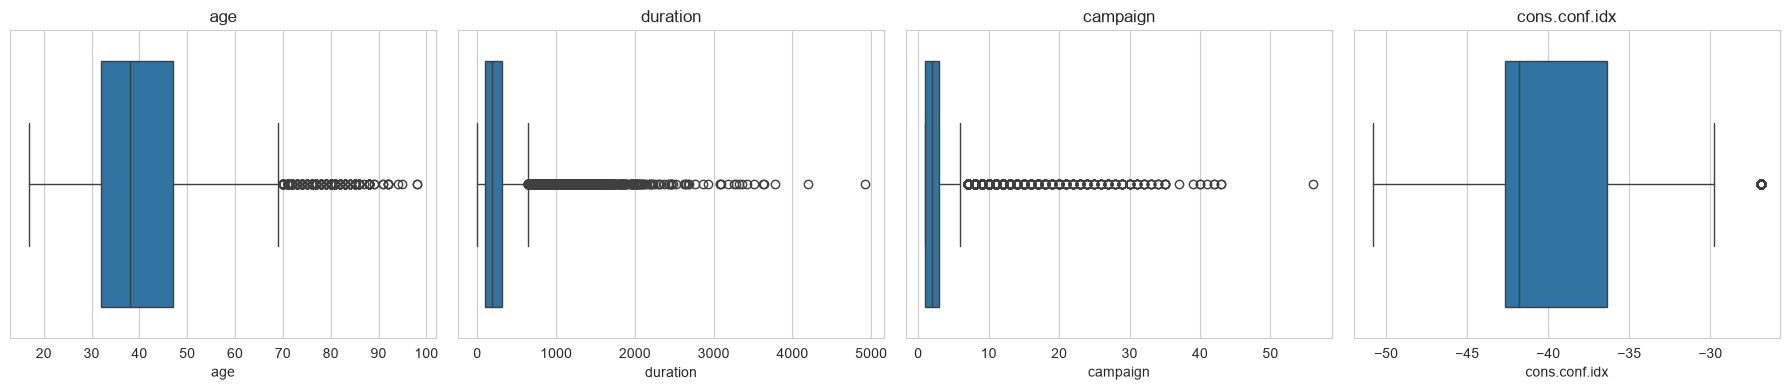

In [15]:
# Boxplots of the columns with outliers
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["age", "duration", "campaign", "cons.conf.idx"]):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Decision:** keep the outliers. They are real values (old clients, long calls, many calls), not errors.
For `pdays` and `previous` the IQR rule is not meaningful: almost all values are 999 / 0.

## 6. Univariate Analysis
### 6.1 Target

y
no     36537
yes     4639
Name: count, dtype: int64
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


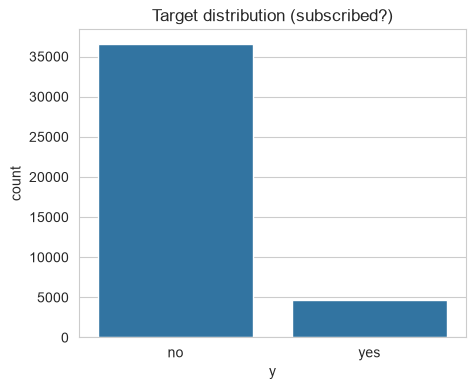

In [16]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=df)
plt.title("Target distribution (subscribed?)")
plt.show()

Only **11%** of clients subscribe → the data is **imbalanced**. A model that always says "no" is 89% accurate, so accuracy alone is misleading.

### 6.2 Numeric Features

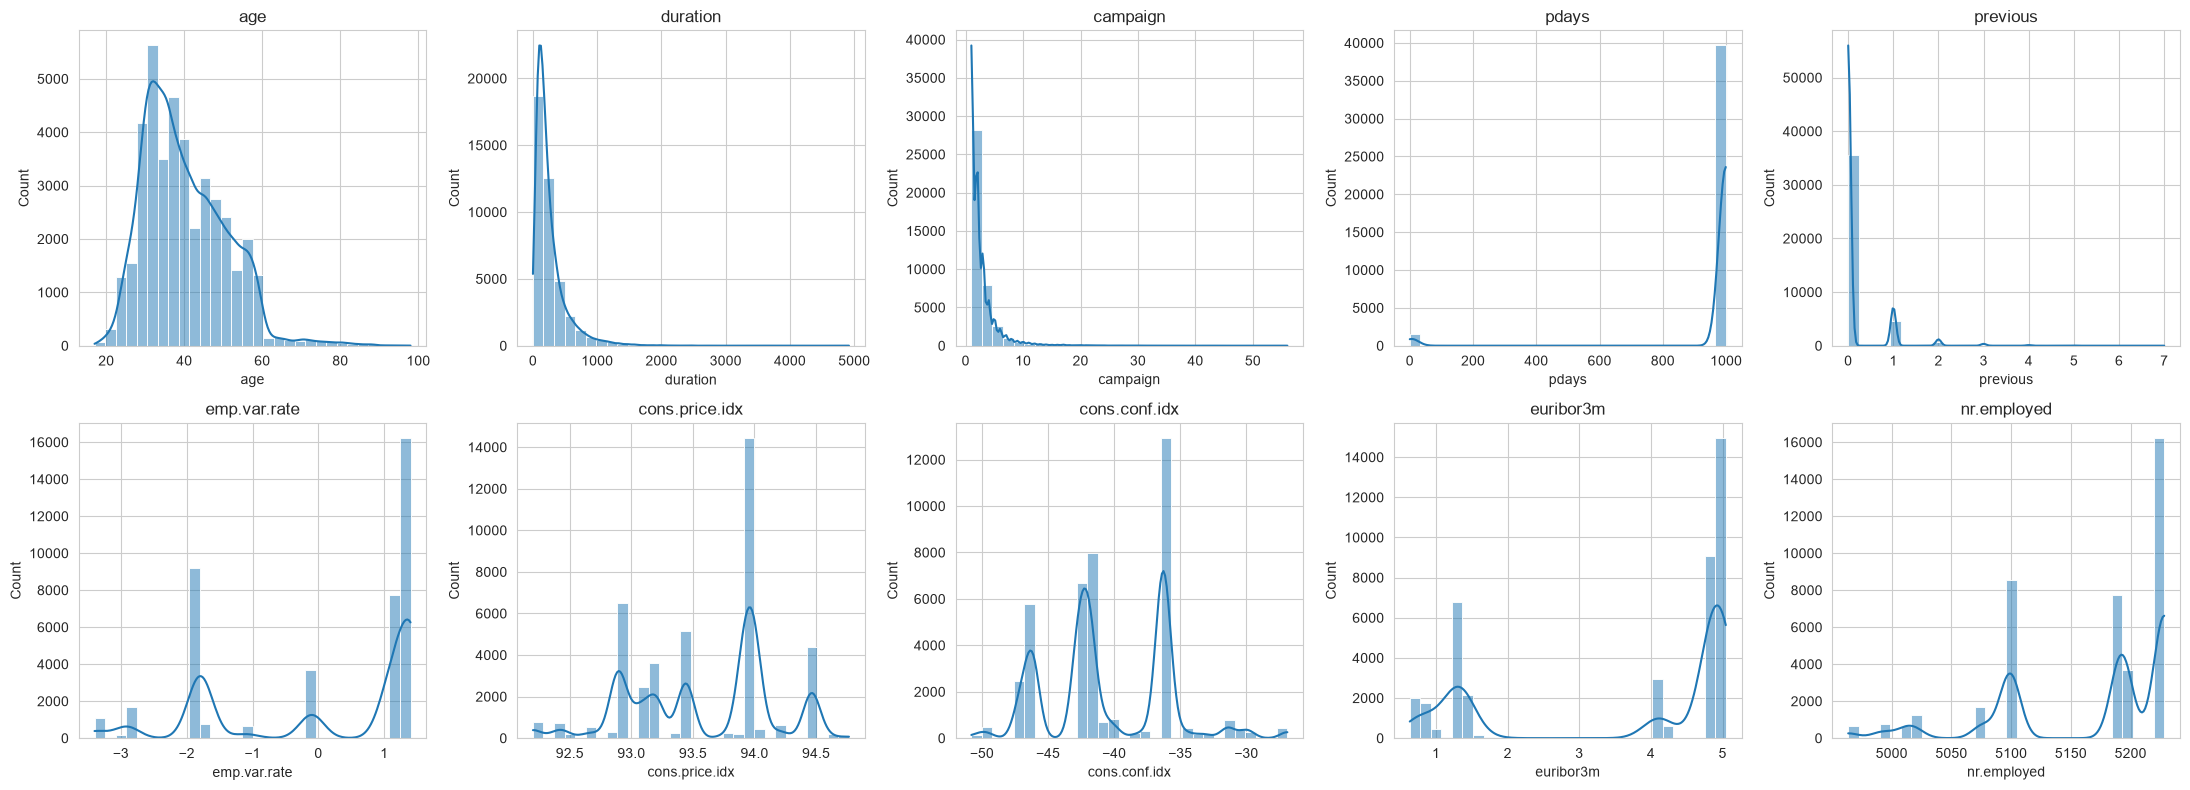

In [17]:
# Histograms with KDE
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [18]:
# Skewness (0 = symmetric, > 1 = strongly right-skewed)
df[num_cols].skew().round(2).sort_values(ascending=False)

campaign          4.76
previous          3.83
duration          3.26
age               0.78
cons.conf.idx     0.30
cons.price.idx   -0.23
euribor3m        -0.71
emp.var.rate     -0.72
nr.employed      -1.04
pdays            -4.92
dtype: float64

- `duration`, `campaign` and `previous` are strongly **right-skewed**.
- `pdays` is almost always 999 (no value recorded).
- `age` is mostly between 25 and 60.

### 6.3 Categorical Features

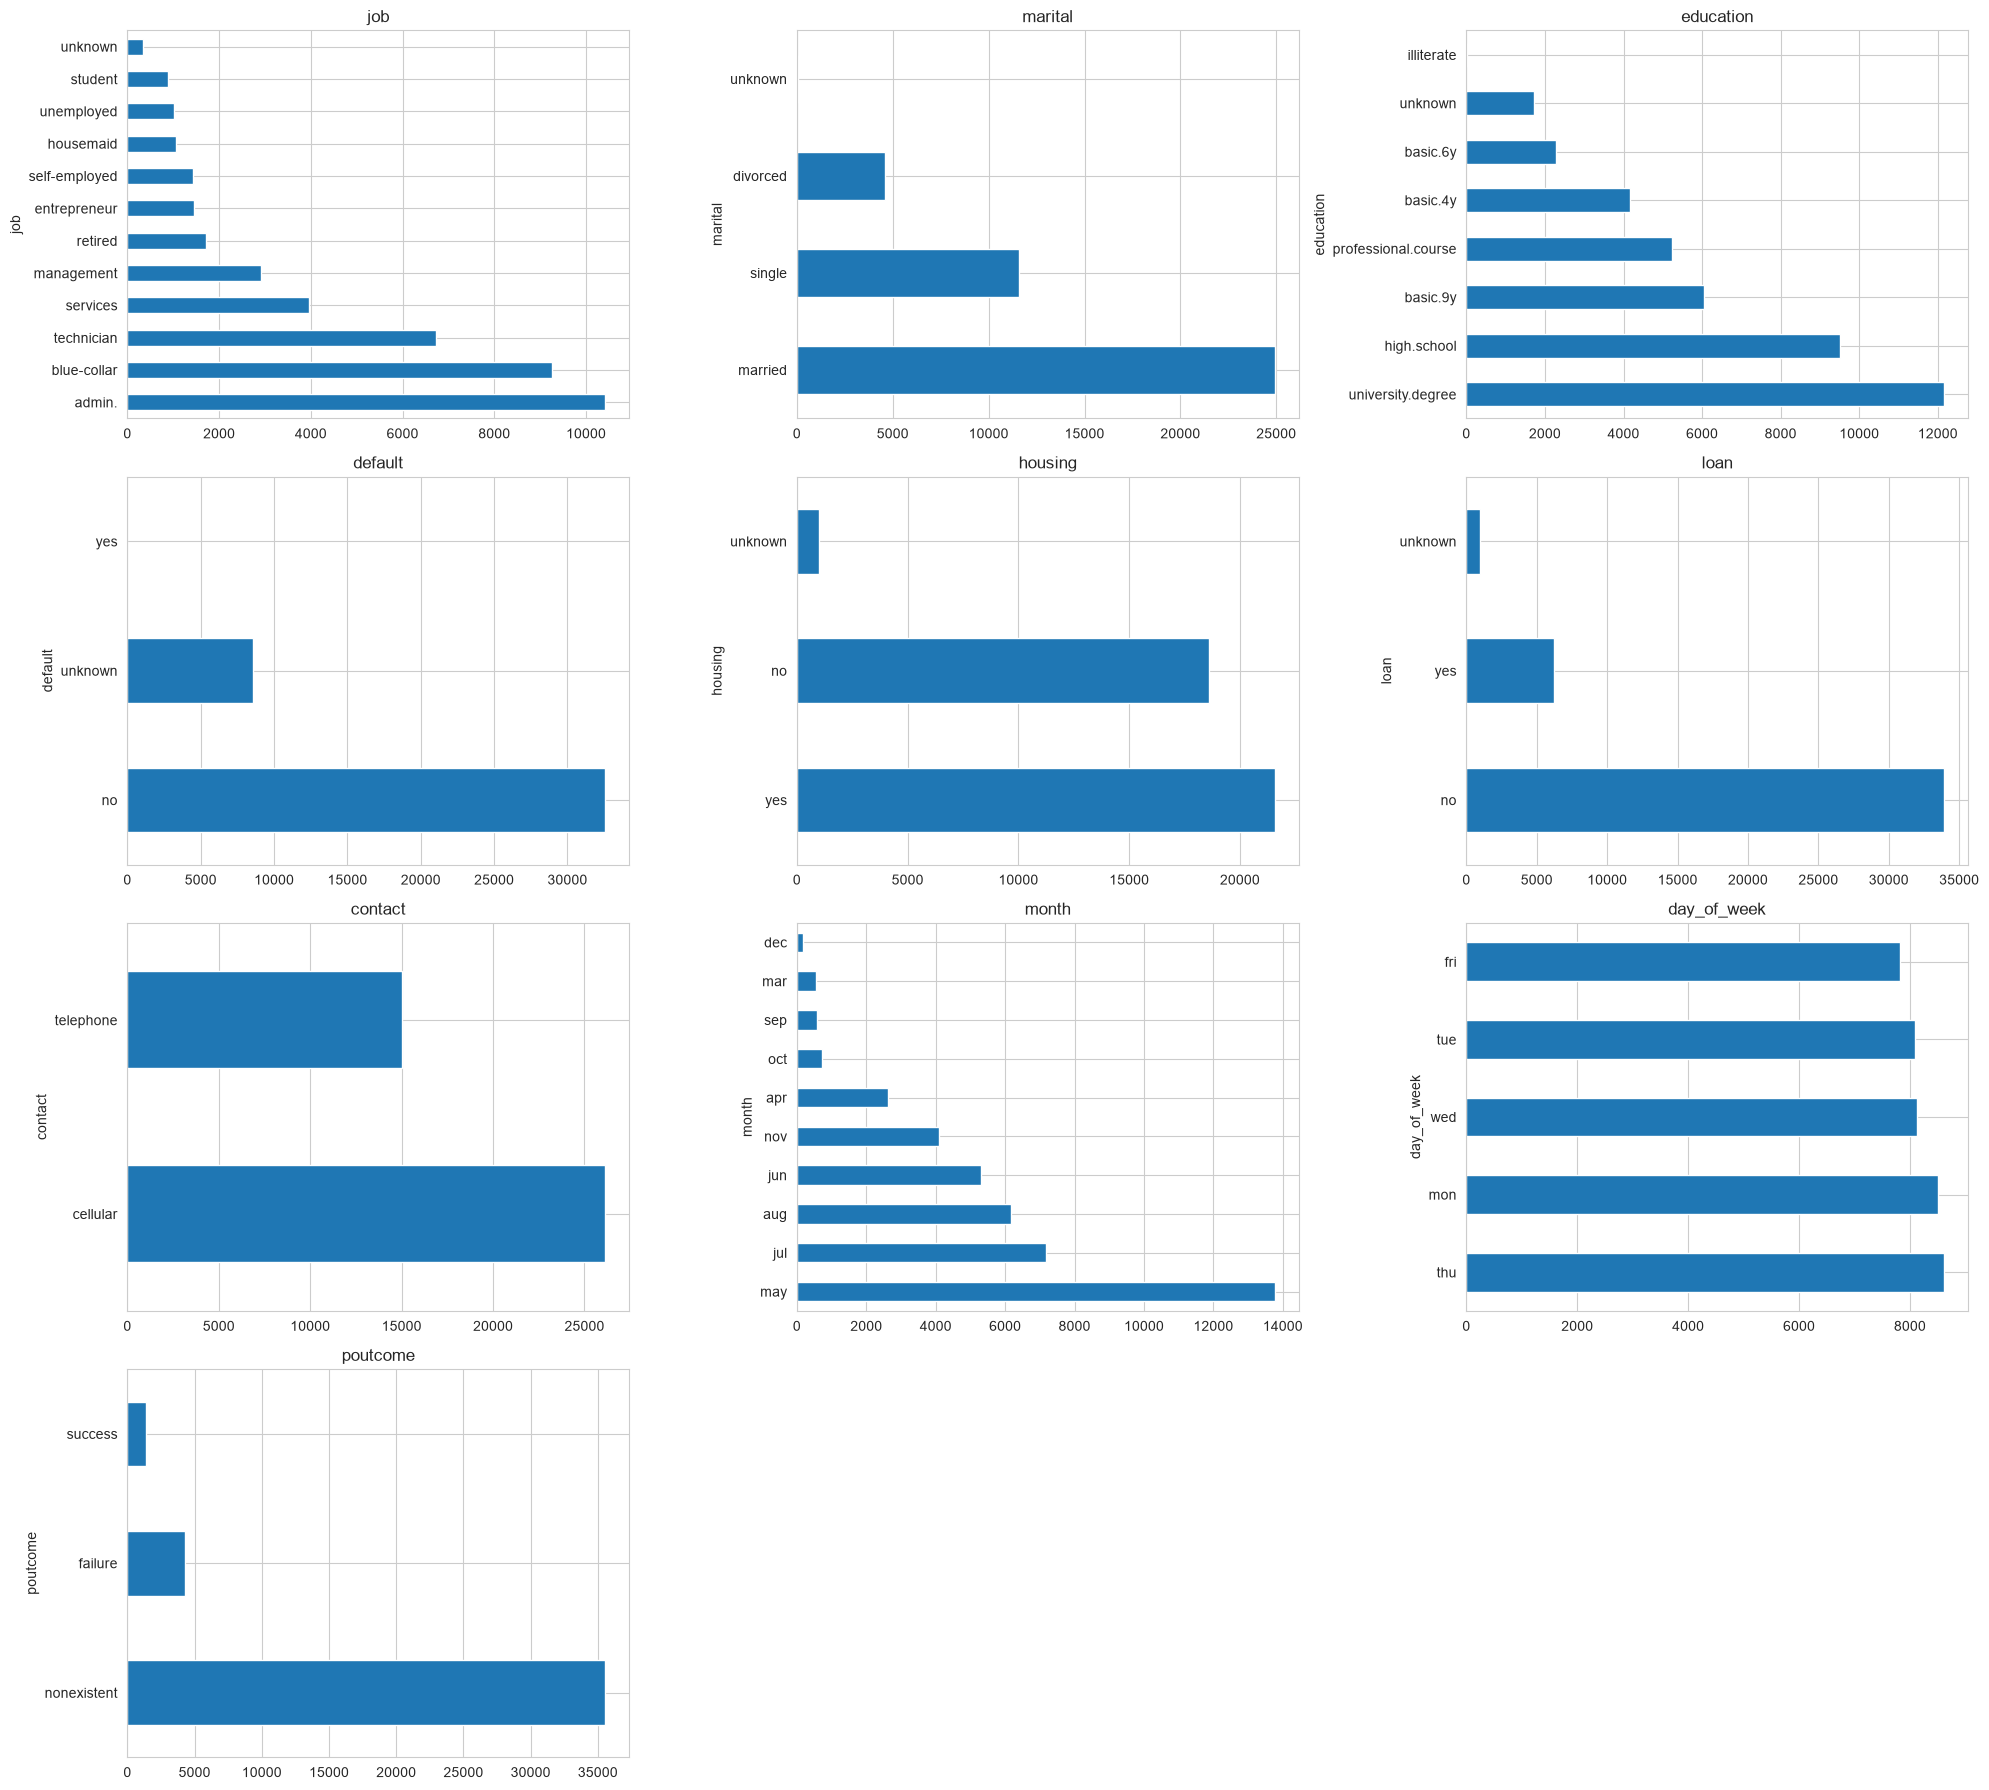

In [19]:
fig, axes = plt.subplots(4, 3, figsize=(20, 18))
for ax, col in zip(axes.ravel(), cat_cols):
    df[col].value_counts().plot(kind="barh", ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

- Most clients are **admin.**, **blue-collar** or **technician**, and **married**.
- Most calls were in **May**; most clients have **no previous campaign** (`poutcome = nonexistent`).

## 7. Bivariate Analysis (Features vs Target)
### 7.1 Numeric vs Target

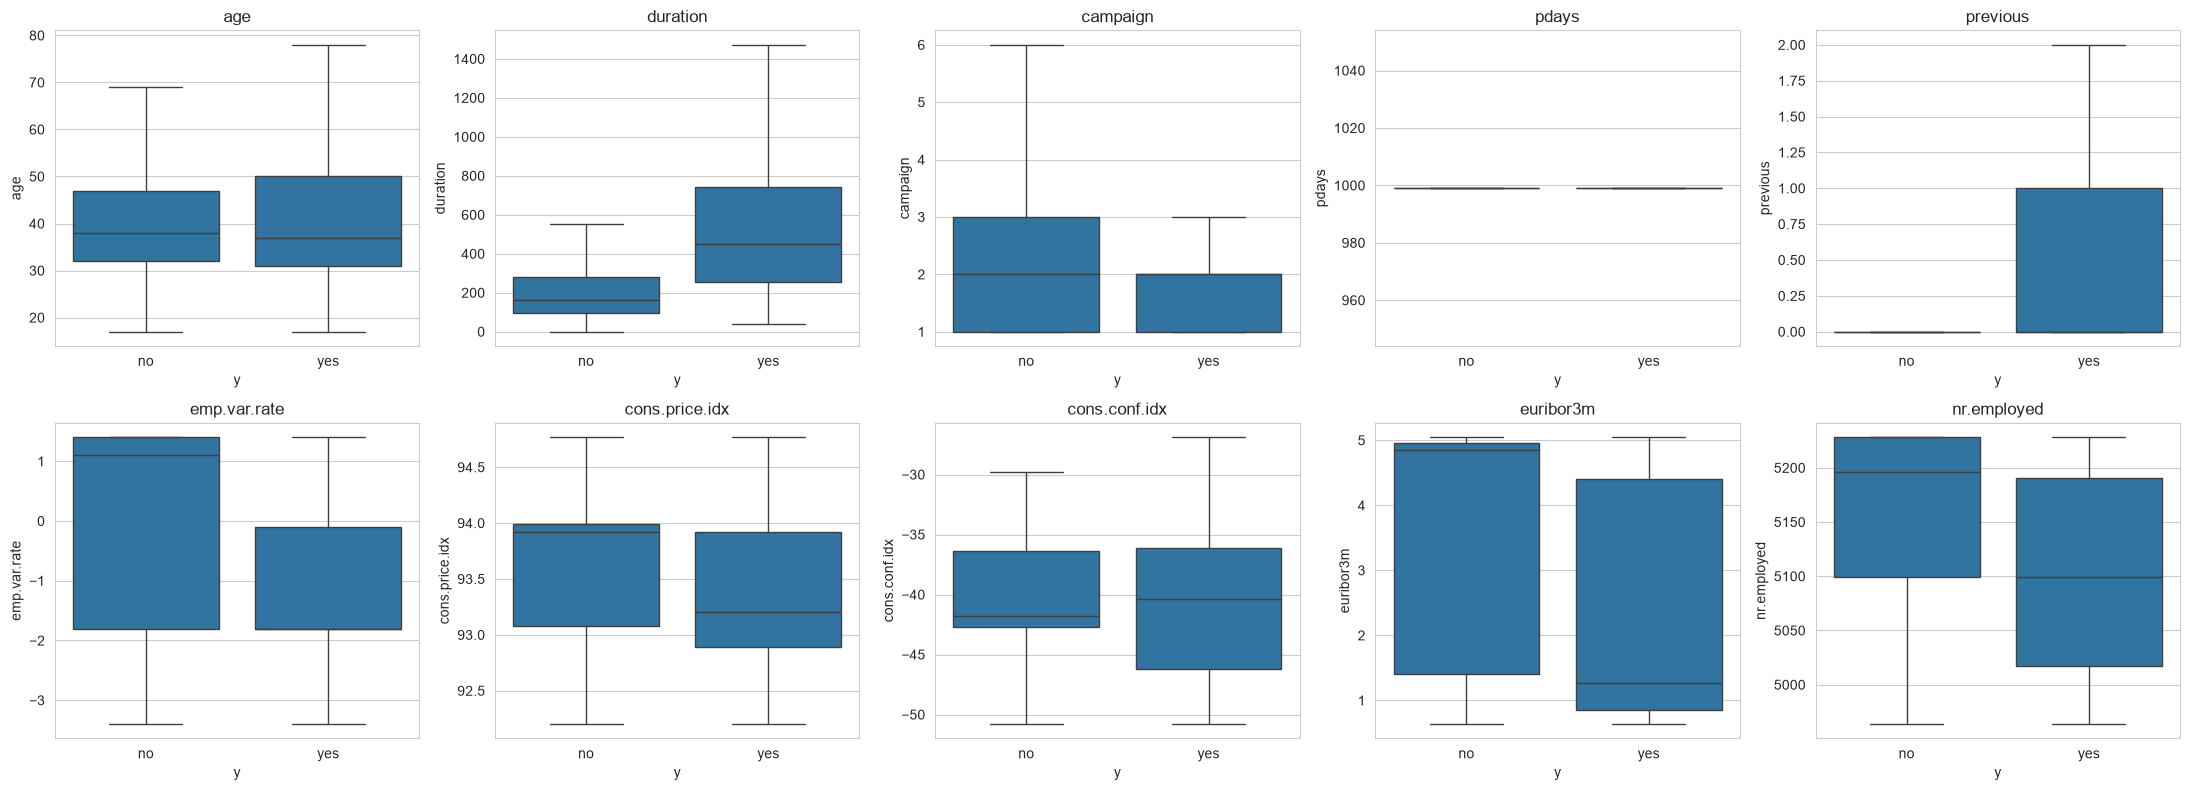

In [20]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [21]:
# Mean of numeric features for "no" vs "yes"
df.groupby(TARGET)[num_cols].mean().T.round(2)

y,no,yes
age,39.91,40.91
duration,220.87,553.26
campaign,2.63,2.05
pdays,984.11,791.99
previous,0.13,0.49
emp.var.rate,0.25,-1.23
cons.price.idx,93.60,93.35
cons.conf.idx,-40.59,-39.79
euribor3m,3.81,2.12
nr.employed,5176.17,5095.12


- **`duration`** is much longer for "yes" — but it is only known **after** the call ends → **data leakage**, it must be removed.
- "Yes" clients were contacted fewer times (`campaign`) and more often in earlier campaigns (`previous`).
- Economic indicators (`euribor3m`, `nr.employed`, `emp.var.rate`) are lower for "yes".

### 7.2 Categorical vs Target

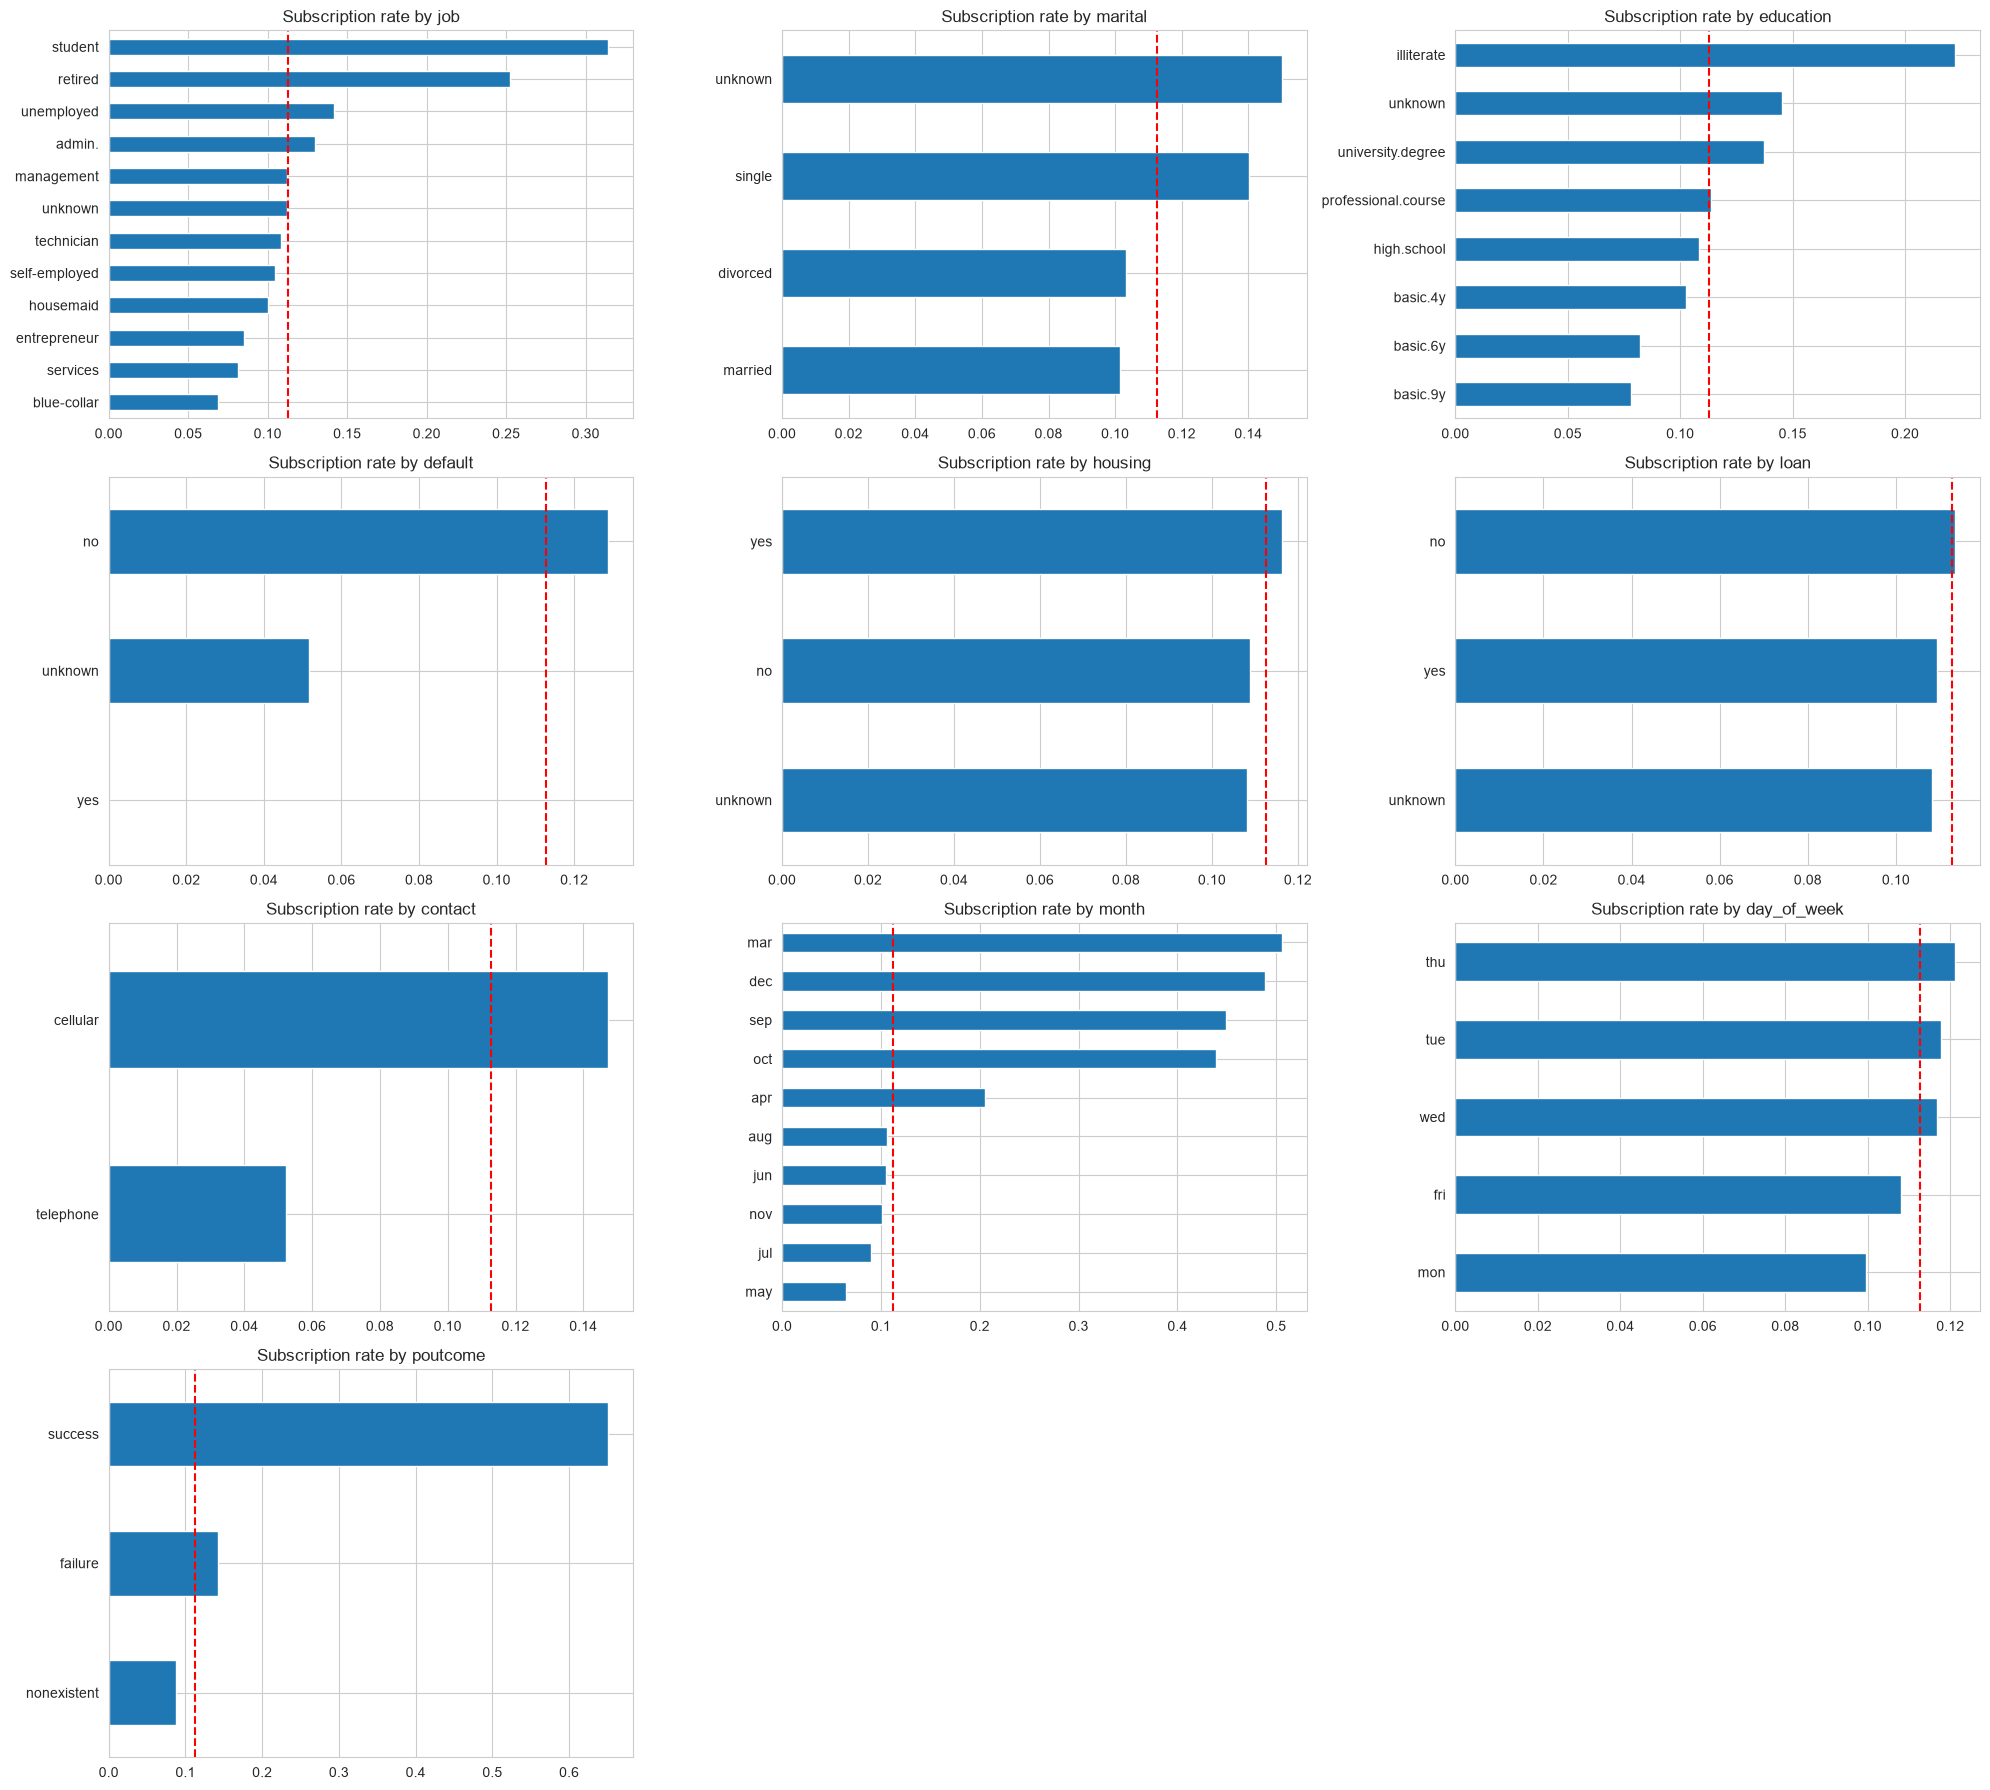

In [22]:
# Subscription rate per category; red line = overall rate
overall = (df[TARGET] == "yes").mean()
fig, axes = plt.subplots(4, 3, figsize=(20, 18))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)[TARGET].apply(lambda s: (s == "yes").mean()).sort_values()
    rate.plot(kind="barh", ax=ax)
    ax.axvline(overall, color="red", ls="--")
    ax.set_title(f"Subscription rate by {col}")
    ax.set_ylabel("")
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [23]:
# Crosstab: previous campaign outcome vs target (row percentages)
pd.crosstab(df["poutcome"], df[TARGET], normalize="index").round(3)

y,no,yes
poutcome,,
failure,0.858,0.142
nonexistent,0.912,0.088
success,0.349,0.651


In [24]:
# Crosstab: contact type vs target
pd.crosstab(df["contact"], df[TARGET], normalize="index").round(3)

y,no,yes
contact,,
cellular,0.853,0.147
telephone,0.948,0.052


### 7.3 Correlation

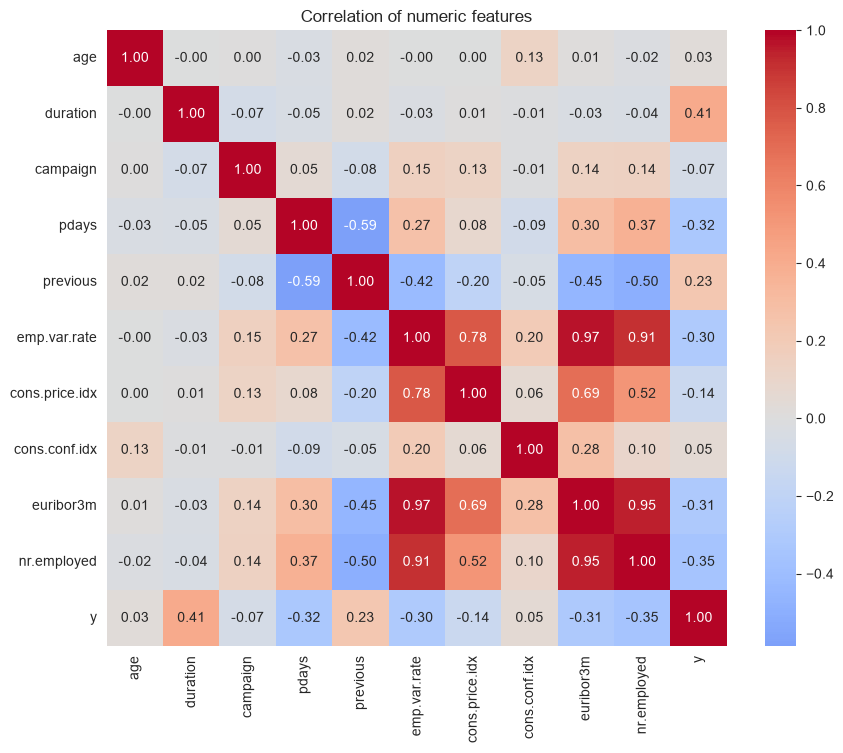

In [25]:
# Numeric features + target as 0/1
corr = df[num_cols].assign(y=(df[TARGET] == "yes").astype(int)).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features")
plt.show()

## 8. Insights
- **Imbalanced target:** only 11% subscribe → use class weights and PR-AUC / F1 instead of accuracy.
- **`duration` leaks the answer** (known only after the call) → removed.
- **Previous success matters most:** 65% of clients with `poutcome = success` subscribe (vs 11% overall).
- **Cellular** contact: 15% subscribe vs 5% by telephone.
- **Months** mar, sep, oct, dec have 44–51% subscription; May is the busiest but lowest (6%).
- **Students (31%)** and **retired (25%)** subscribe most; blue-collar the least (7%).
- **Economic indicators** are strongly correlated with each other (`euribor3m`, `nr.employed`, `emp.var.rate` > 0.9) and negatively with the target (≈ -0.3): fewer subscriptions when rates and employment are high.

## 9. Preprocessing
1. `pdays = 999` means *no value recorded* → new flag `pdays_recorded` (1 = `pdays` has a value), and 999 → -1
2. Drop `duration` (data leakage)
3. Target `y` → 1 (yes) / 0 (no)

**Note on `pdays = 999`:** it does not always mean *never contacted*. 4,110 clients have `previous > 0` (contacted before) but `pdays = 999`. To know whether a client was contacted before, use `previous`.

Encoding, scaling and the train / validation / test split are done in `src/preprocess.py` (fitted on the training set only).

In [26]:
df_clean = df.copy()

# 1. Flag: is pdays recorded? Then replace 999 so it does not distort scaling
df_clean["pdays_recorded"] = (df_clean["pdays"] != 999).astype(int)
df_clean["pdays"] = df_clean["pdays"].replace(999, -1)

# 2. Remove the leaking feature
df_clean = df_clean.drop(columns=["duration"])

# 3. Target as 0/1
df_clean[TARGET] = (df_clean[TARGET] == "yes").astype(int)

df_clean.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,pdays_recorded
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [27]:
# Final check
print("Shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Identical rows (with y):", df_clean.duplicated().sum())
print("Rows repeating a feature profile (without y):", df_clean.drop(columns=TARGET).duplicated().sum())
print("Positive rate:", round(df_clean[TARGET].mean(), 3))

Shape: (41176, 21)
Missing values: 0
Identical rows (with y): 1772
Rows repeating a feature profile (without y): 2009
Positive rate: 0.113


**Note on identical rows:** after removing `duration`, 1,772 rows repeat another row exactly, and 2,009 rows repeat a feature profile (ignoring `y`); 237 profiles appear with both "yes" and "no".
There is no client ID, so we cannot tell whether these are different calls or repeated records. They are kept, and `src/preprocess.py` puts rows with the same feature profile in the same split, so the same profile never appears in both train and test.

## 10. Save the Cleaned Dataset

In [28]:
os.makedirs("data", exist_ok=True)
df_clean.to_csv("data/bank_clean.csv", index=False)

# Reload to confirm it was saved correctly
check = pd.read_csv("data/bank_clean.csv")
print(check.shape)
check.head()

(41176, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,pdays_recorded
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,-1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
